In [1]:
import sys, pandas, numpy, pyarrow, matplotlib
print(sys.executable)
print(pandas.__version__, numpy.__version__, pyarrow.__version__)


c:\Users\aldai\Documents\FireWatcher\.venv\Scripts\python.exe
3.1.1 2.5.4 26.0.1


In [2]:
import sys; print(sys.executable)

c:\Users\aldai\Documents\FireWatcher\.venv\Scripts\python.exe


# Paso 1: configuración

In [3]:
from pathlib import Path
import json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data_NASA_2026"
OUT = ROOT / "data_processed"
OUT.mkdir(exist_ok=True)

GRID = 0.01  # tamaño de celda en grados (~1.1 km)
BBOX = dict(lat_min=14.0, lat_max=33.5, lon_min=-118.5, lon_max=-86.0)  # México con margen

FILES = {
    "modis":        RAW / "modis_mexico_2000_2025.csv",
    "viirs-snpp":   RAW / "viirs-snpp_mexico_2012_2025.csv",
    "viirs-noaa20": RAW / "viirs-noaa20_mexico_2018_2025.csv",
}
quality = {"limpieza": {}}  # aquí se registra cada decisión con números (para la vista About)


# Paso 2: cargar y unificar el esquema
MODIS y VIIRS nombran distinto las columnas de brillo, así que se renombran a nombres comunes.

In [4]:
RENAME = {"brightness": "bright_main", "bright_t31":"bright_secondary",
          "bright_ti4": "bright_main", "bright_ti5":"bright_secondary"}

def cargar(path):
    df = pd.read_csv(path, dtype ={"acq_time": "int32", "confidence": "string", "version": "string","satellite":"string","type":"int8"})

    return df.rename(columns=RENAME)

raw = pd.concat([cargar(p) for p in FILES.values()], ignore_index=True)
quality["filas_crudas"] = raw["serie"].value_counts().to_dict()
print(quality["filas_crudas"])
print(raw.dtypes)

{'viirs-snpp': 4225823, 'viirs-noaa20': 2394833, 'modis': 1685470}
latitude            float64
longitude           float64
bright_main         float64
scan                float64
track               float64
acq_date                str
acq_time              int32
satellite            string
instrument              str
confidence           string
version              string
bright_secondary    float64
frp                 float64
daynight                str
type                   int8
serie                   str
dtype: object


# Paso 3: normalizar fechas, satélites y sensor

In [5]:
raw["satellite"] = raw["satellite"].map({"Terra": "Terra", "Aqua": "Aqua", "N": "SNPP", "N20": "NOAA20"}).astype("category")
raw["sensor"] = raw["instrument"].astype("category")
raw["serie"] = raw["serie"].astype("category")
raw["daynight"] = raw["daynight"].astype("category")

raw["date"] = pd.to_datetime(raw["acq_date"], format="%Y-%m-%d")
t = raw["acq_time"]  # HHMM como entero: 423 = 04:23 UTC
raw["datetime_utc"] = raw["date"] + pd.to_timedelta((t // 100) * 60 + t % 100, unit="min")
raw["year"] = raw["date"].dt.year.astype("int16")
raw["month"] = raw["date"].dt.month.astype("int8")

print(raw["satellite"].value_counts(dropna=False))  # no debe haber NaN
raw = raw.drop(columns=["acq_date", "acq_time", "instrument"])


satellite
SNPP      4225823
NOAA20    2394833
Aqua       879347
Terra      806123
Name: count, dtype: int64


# Paso 4: explorar (EDA)
4a. Versiones por serie y periodo. Esta tabla es clave para el paso 6.

In [6]:
ver = raw.groupby(["serie", "version"], observed=True)["date"].agg(["min", "max", "count"])
ver


min        max    count
serie        version                               
modis        6.03    2018-01-01 2022-12-31   346984
             6.2     2000-11-01 2017-12-31  1118454
             61.03   2023-01-01 2025-12-31   220032
viirs-noaa20 2       2018-04-01 2025-12-31  2394833
viirs-snpp   2       2012-01-20 2025-12-31  4225823

4b. Conteos por año y sensor

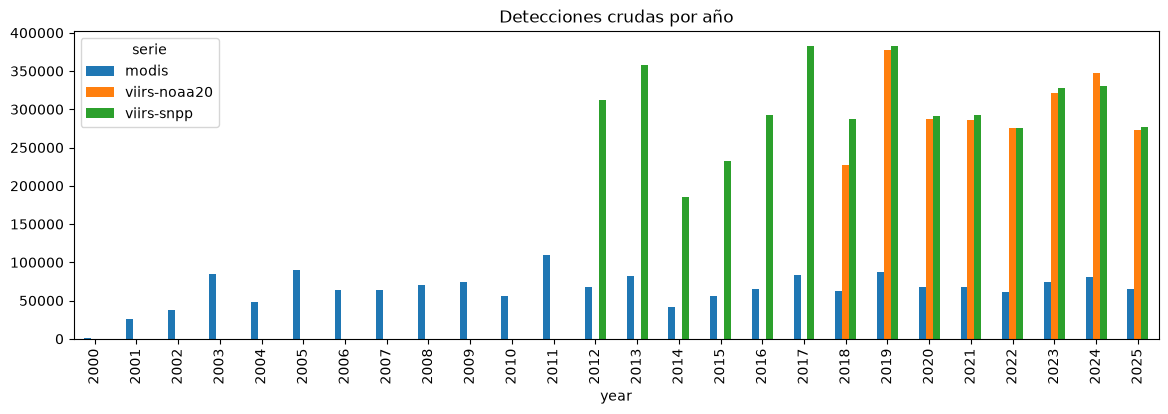

In [7]:
raw.groupby(["year", "serie"], observed=True).size().unstack().plot(kind="bar", figsize=(14, 4), title="Detecciones crudas por año")
plt.show()


4c. Comprobar el significado de type

type                0     1       2     3
serie                                    
modis         1560516  2937  114494  7523
viirs-noaa20  2109393  2215  278777  4448
viirs-snpp    3731752  8790  478541  6740


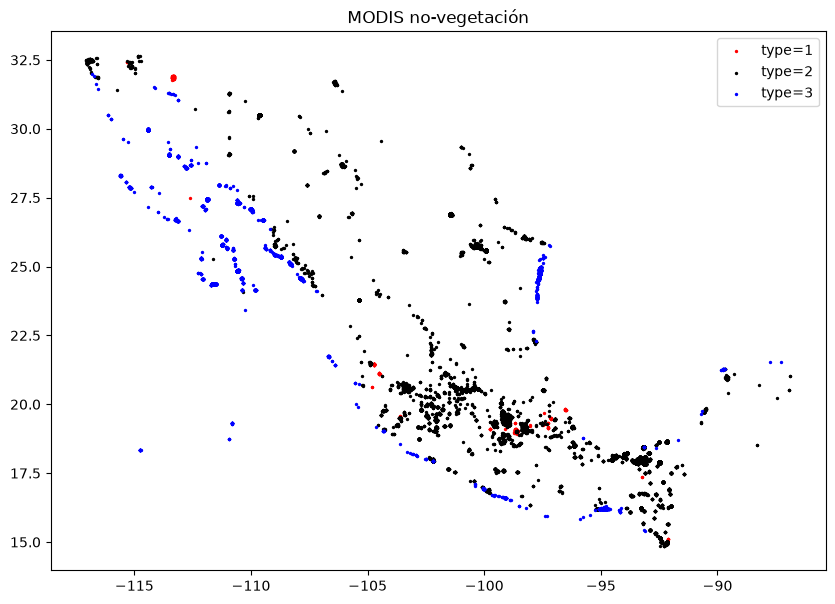

In [8]:
print(raw.groupby(["serie", "type"], observed=True).size().unstack(fill_value=0))

no_veg = raw[(raw.sensor == "MODIS") & (raw.type != 0)]
fig, ax = plt.subplots(figsize=(10, 7))
for tp, color in [(1, "red"), (2, "black"), (3, "blue")]:
    d = no_veg[no_veg.type == tp]
    ax.scatter(d.longitude, d.latitude, s=2, c=color, label=f"type={tp}")
ax.legend(); ax.set_title("MODIS no-vegetación"); plt.show()


# Paso 5: normalizar la confianza

In [9]:
conf = pd.Series(pd.NA, index=raw.index, dtype="object")
m = raw.sensor == "MODIS"
c = pd.to_numeric(raw.loc[m, "confidence"], errors="coerce")
conf.loc[m] = pd.cut(c, [-np.inf, 30, 80, np.inf], right=False, labels=["low", "nominal", "high"]).astype("object")
conf.loc[~m] = raw.loc[~m, "confidence"].map({"l": "low", "n": "nominal", "h": "high"})
raw["conf_level"] = pd.Categorical(conf, categories=["low", "nominal", "high"])
raw = raw.drop(columns=["confidence"])

print(raw.groupby(["serie", "conf_level"], observed=True).size().unstack())


conf_level       low  nominal    high
serie                                
modis          77625  1134327  473518
viirs-noaa20  301802  1968103  124928
viirs-snpp    509922  3471268  244633


# Paso 6: limpieza básica

In [10]:
def paso(df, keep, nombre):
    n = int((~keep).sum())
    quality["limpieza"][nombre] = n
    print(f"{nombre}: -{n:,}")
    return df[keep].reset_index(drop=True)

# 6a. duplicados exactos
raw = paso(raw, ~raw.duplicated(["latitude", "longitude", "datetime_utc", "satellite"]), "duplicados_exactos")

# 6b. coordenadas fuera de México o inválidas
dentro = raw.latitude.between(BBOX["lat_min"], BBOX["lat_max"]) & raw.longitude.between(BBOX["lon_min"], BBOX["lon_max"])
raw = paso(raw, dentro, "fuera_de_bbox")

# 6c. sin confianza válida
raw = paso(raw, raw.conf_level.notna(), "confianza_invalida")

# 6d. versiones NRT en fechas donde ya hay versión estándar
STD = {"modis": {"6.1", "6.2"}, "viirs-snpp": {"2"}, "viirs-noaa20": {"2"}}  # ⚠️ AJUSTA con la tabla del paso 4a
raw["is_std"] = False
for s, vs in STD.items():
    raw.loc[(raw.serie == s) & raw.version.isin(vs), "is_std"] = True
con_std = set(zip(raw.loc[raw.is_std, "serie"].astype(str), raw.loc[raw.is_std, "date"]))
tiene_std = pd.Series([(s, d) in con_std for s, d in zip(raw.serie.astype(str), raw.date)], index=raw.index)
raw = paso(raw, raw.is_std | ~tiene_std, "nrt_con_estandar_disponible")


duplicados_exactos: -4
fuera_de_bbox: -0
confianza_invalida: -0
nrt_con_estandar_disponible: -0


# Paso 7: asignar la rejilla de 1 km

In [11]:
raw["cell_row"] = np.floor(raw.latitude / GRID).astype("int32")
raw["cell_col"] = np.floor(raw.longitude / GRID).astype("int32")
raw["cell_id"] = raw.cell_row.astype("int64") * 100_000 + (raw.cell_col.astype("int64") + 50_000)
print(raw.cell_id.nunique(), "celdas con alguna detección")


720844 celdas con alguna detección


# Paso 8: máscara de fuentes fijas (corrige el bug de VIIRS v2)

In [12]:
fijas = raw.loc[(raw.sensor == "MODIS") & raw.type.isin([1, 2, 3]), ["cell_row", "cell_col"]].drop_duplicates()
vecinos = [(dr, dc) for dr in (-1, 0, 1) for dc in (-1, 0, 1)]  # 3x3: celda + 1 de margen
mask = pd.concat([fijas.assign(cell_row=fijas.cell_row + dr, cell_col=fijas.cell_col + dc) for dr, dc in vecinos]).drop_duplicates()
mask["cell_id"] = mask.cell_row.astype("int64") * 100_000 + (mask.cell_col.astype("int64") + 50_000)
print(len(mask), "celdas en la máscara")

raw["en_mascara"] = raw.cell_id.isin(mask.cell_id.values)

# Qué se elimina, por serie y año (para documentarlo)
quitar_viirs = (raw.sensor == "VIIRS") & raw.en_mascara & (raw.type == 0)
print(raw[quitar_viirs].groupby(["serie", "year"], observed=True).size().unstack(0))

clean = paso(raw, raw.type == 0, "type_no_vegetacion")
clean = paso(clean, ~((clean.sensor == "VIIRS") & clean.en_mascara), "viirs_en_mascara_fuentes_fijas")
del raw


17312 celdas en la máscara
serie  viirs-noaa20  viirs-snpp
year                           
2012            NaN      3096.0
2013            NaN      4590.0
2014            NaN      4063.0
2015            NaN      3787.0
2016            NaN      5214.0
2017            NaN      5563.0
2018         2664.0      4795.0
2019         5683.0      5977.0
2020         5318.0      5356.0
2021         6483.0      6466.0
2022         5367.0      5198.0
2023         5385.0      5193.0
2024         8212.0      8134.0
2025         7348.0      7232.0
type_no_vegetacion: -904,465
viirs_en_mascara_fuentes_fijas: -121,124


8b. Diagnóstico de fuentes industriales residuales. Busca las celdas que se activan casi todo el año, todos los años

In [13]:
dias = clean.groupby("cell_id").agg(dias=("date", "nunique"), lat=("latitude", "mean"), lon=("longitude", "mean"))
dias.sort_values("dias", ascending=False).head(20)


,dias,lat,lon
cell_id,,,
183940717,443,18.393142,-92.827856
206039665,378,20.602463,-103.345194
188340272,363,18.836631,-97.275308
190039574,358,19.007036,-104.257935
257239989,348,25.722991,-100.104311
181040565,341,18.104168,-94.345495
184140378,335,18.411922,-96.213488
175940670,307,17.595342,-93.295676
180740695,298,18.075208,-93.045026


8c. Filtro de persistencia: fuentes industriales (CFE, Pemex, quemadores) que la máscara de MODIS no atrapó.
Una celda se marca como fuente fija si tiene ≥100 días activos, actividad en ≥10 de los 12 meses y ≥15% de sus días en julio–octubre (temporada de lluvias, cuando casi no hay incendios). Ver `docs/metodologia_armonizacion.md` §4.3.

In [14]:
c = clean[["cell_id", "date", "month"]].drop_duplicates()
c["lluvia"] = c.month.between(7, 10)
p = c.groupby("cell_id").agg(dias=("date", "size"), meses=("month", "nunique"), lluvia=("lluvia", "mean"))

persistentes = p[(p.dias >= 100) & (p.meses >= 10) & (p.lluvia >= 0.15)]
print(len(persistentes), "celdas persistentes")  # se esperan ~171
display(persistentes.sort_values("dias", ascending=False).head(10))

clean = paso(clean, ~clean.cell_id.isin(persistentes.index), "persistencia_fuentes_fijas")

# se agregan a la máscara exportada, con el motivo
mask["motivo"] = "modis_type_1_2_3"
extra = pd.DataFrame({"cell_id": persistentes.index.values})
extra["cell_row"] = extra.cell_id // 100_000
extra["cell_col"] = extra.cell_id % 100_000 - 50_000
extra["motivo"] = "persistencia"
mask = pd.concat([mask, extra], ignore_index=True)
del c, p

171 celdas persistentes


,dias,meses,lluvia
cell_id,,,
183940717,443,12,0.320542
206039665,378,12,0.190476
188340272,363,12,0.349862
190039574,358,12,0.162011
257239989,348,12,0.643678
181040565,341,12,0.313783
184140378,335,12,0.197015
175940670,307,12,0.201954
180740695,298,12,0.234899


persistencia_fuentes_fijas: -38,555


# Paso 9: celda-día armonizado

In [15]:
BIT = {"Terra": 1, "Aqua": 2, "SNPP": 4, "NOAA20": 8}
clean["bit"] = clean.satellite.map(BIT).astype("int8")

pres = clean[["cell_id", "date", "bit"]].drop_duplicates()
sensors = pres.groupby(["cell_id", "date"])["bit"].sum().rename("sensors")  # bits distintos: suma = OR

cd = (clean.groupby(["cell_id", "date"])
      .agg(n_det=("bit", "size"), frp_max=("frp", "max"), frp_sum=("frp", "sum"),
           cell_row=("cell_row", "first"), cell_col=("cell_col", "first"))
      .join(sensors).reset_index())
cd["year"] = cd.date.dt.year.astype("int16")
cd["month"] = cd.date.dt.month.astype("int8")
cd["lat_c"] = (cd.cell_row + 0.5) * GRID
cd["lon_c"] = (cd.cell_col + 0.5) * GRID
cd["has_modis"] = (cd.sensors & 3) > 0   # Terra o Aqua
cd["has_base"] = (cd.sensors & 7) > 0    # MODIS ∪ SNPP: serie base, consistente desde 2012
cd["has_terra"] = (cd.sensors & 1) > 0
print(len(cd), "celdas-día")


4237181 celdas-día


# Paso 10: calibración del periodo solo-MODIS

month
1     3.380
2     3.763
3     3.540
4     3.270
5     3.572
6     4.176
7     4.119
8     3.762
9     3.395
10    3.843
11    4.084
12    3.526
dtype: float64


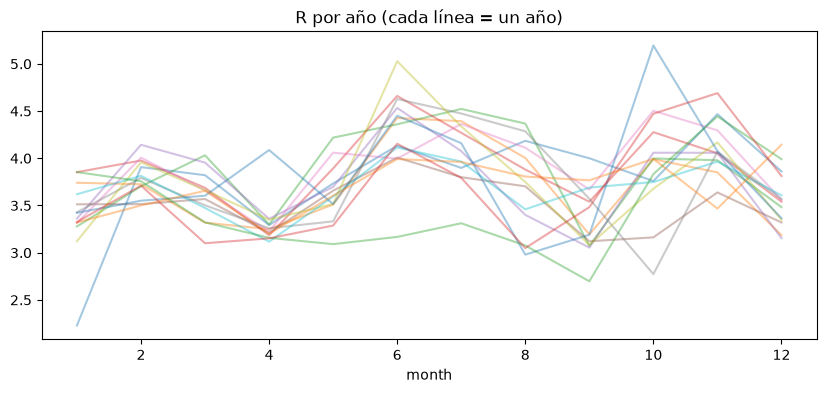

Primera detección Aqua: 2002-07-04
month
1     2.542
2     2.463
3     2.536
4     2.175
5     2.071
6     2.070
7     2.118
8     2.148
9     2.023
10    2.105
11    2.343
12    2.604
dtype: float64


In [16]:
mens = cd.groupby(["year", "month"]).agg(modis=("has_modis", "sum"), base=("has_base", "sum"),
                                         terra=("has_terra", "sum"), todas=("sensors", "size"))

# R: cuánto "más" ve MODIS∪SNPP que MODIS solo, por mes del año (traslape 2012-2025)
over = mens.loc[2012:2025]
R_mes = over.groupby("month").base.sum() / over.groupby("month").modis.sum()
R_anual = (over.base / over.modis).unstack()  # para revisar estabilidad
print(R_mes.round(3))
R_anual.T.plot(legend=False, alpha=.4, figsize=(10, 4), title="R por año (cada línea = un año)"); plt.show()

# A: corrección por la ausencia de Aqua (solo Terra antes de su primera fecha)
first_aqua = clean.loc[clean.satellite == "Aqua", "date"].min()
print("Primera detección Aqua:", first_aqua.date())
ref = mens.loc[2003:2011]
A_mes = ref.groupby("month").modis.sum() / ref.groupby("month").terra.sum()
print(A_mes.round(3))


Peso por celda-día. Así el backend solo tiene que sumar peso dentro del bbox:

In [17]:
cd["peso"] = 0.0
post = cd.year >= 2012
cd.loc[post & cd.has_base, "peso"] = 1.0
pre = (~post) & cd.has_modis
cd.loc[pre, "peso"] = cd.loc[pre, "month"].map(R_mes).values
pre_aqua = pre & (cd.date < first_aqua)
cd.loc[pre_aqua, "peso"] *= cd.loc[pre_aqua, "month"].map(A_mes).values

quality["anio_parcial"] = [2000]  # MODIS empieza en nov-2000


# Paso 11: validación visual

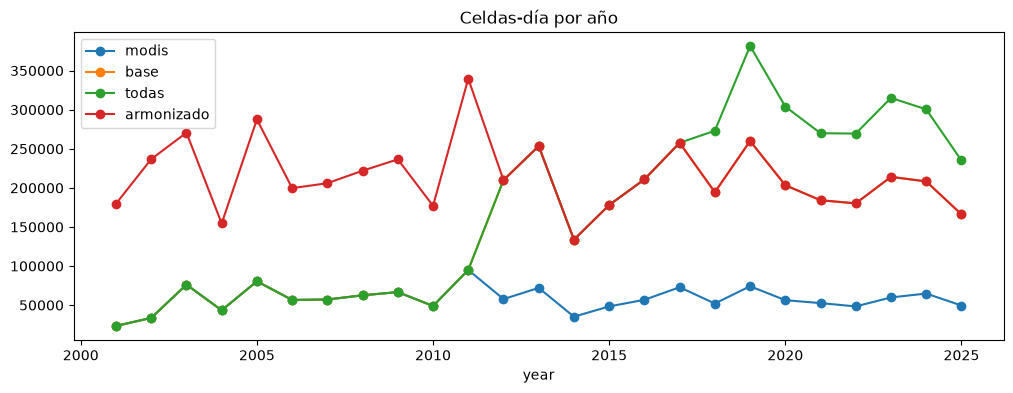

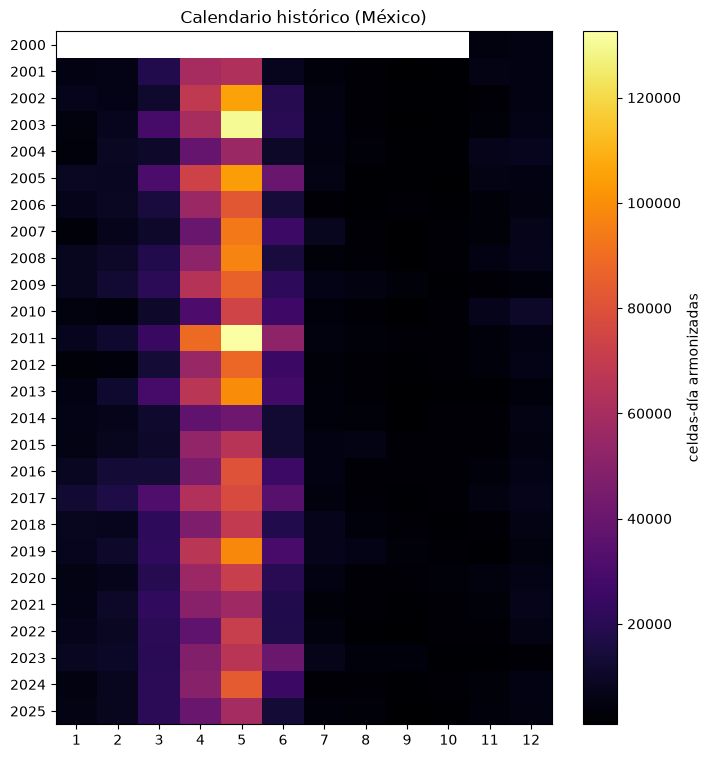

In [18]:
anual = cd.groupby("year").agg(modis=("has_modis", "sum"), base=("has_base", "sum"),
                               todas=("sensors", "size"), armonizado=("peso", "sum"))
anual.drop(2000).plot(figsize=(12, 4), marker="o", title="Celdas-día por año"); plt.show()

cal = cd.groupby(["year", "month"]).peso.sum().unstack()
plt.figure(figsize=(8, 9)); plt.imshow(cal, aspect="auto", cmap="inferno")
plt.yticks(range(len(cal)), cal.index); plt.xticks(range(12), range(1, 13))
plt.colorbar(label="celdas-día armonizadas"); plt.title("Calendario histórico (México)"); plt.show()


Assertions finales:

In [19]:
assert not cd.duplicated(["cell_id", "date"]).any()
assert clean[["latitude", "longitude", "datetime_utc", "conf_level", "satellite"]].notna().all().all()
assert sum(quality["filas_crudas"].values()) - sum(quality["limpieza"].values()) == len(clean)
print("todo OK")


todo OK


# Paso 12: exportar

In [20]:
cols = ["latitude", "longitude", "datetime_utc", "date", "year", "month", "satellite", "sensor",
        "conf_level", "frp", "bright_main", "bright_secondary", "daynight", "cell_id"]
shutil.rmtree(OUT / "hotspots", ignore_errors=True)  # evita duplicar al re-correr
clean[cols].to_parquet(OUT / "hotspots", partition_cols=["year"], compression="zstd", index=False)

cd.drop(columns=["has_terra"]).to_parquet(OUT / "cell_days.parquet", compression="zstd", index=False)
mask[["cell_id", "cell_row", "cell_col", "motivo"]].to_parquet(OUT / "static_mask.parquet", index=False)

json.dump({"grid_deg": GRID, "R_mes": R_mes.round(4).to_dict(), "A_mes": A_mes.round(4).to_dict(),
           "first_aqua": str(first_aqua.date()), "base": "MODIS ∪ VIIRS-SNPP"},
          open(OUT / "calibration_factors.json", "w"), indent=2)
json.dump({k: {str(a): int(b) for a, b in v.items()} if isinstance(v, dict) else v for k, v in quality.items()},
          open(OUT / "quality_report.json", "w"), indent=2, default=str)
json.dump({"years": sorted(int(y) for y in cd.year.unique()), "default_year": int(cd.year.max()),
           "sensors": ["MODIS Terra", "MODIS Aqua", "VIIRS S-NPP", "VIIRS NOAA-20"],
           "partial_years": [2000]},
          open(OUT / "meta.json", "w"), indent=2)

for p in OUT.rglob("*"):
    if p.is_file() and "hotspots" not in p.parts: print(p.name, f"{p.stat().st_size/1e6:.1f} MB")

calibration_factors.json 0.0 MB
cell_days.parquet 39.7 MB
meta.json 0.0 MB
quality_report.json 0.0 MB
static_mask.parquet 0.2 MB
